LABORATORIO 2 TERCIO 2

## JUAN DIEGO GAITAN
## JUAN DIEGO MURILLO

# INSTRUCCIONES

## OBJETIVOS

Desarrollar competencias básicas para:

1. Comprender el perceptrón como modelo fundamental de aprendizaje.
2. Implementar el paso *forward* (predicción) y *backward* (gradientes) de una neurona.
3. Aplicar el algoritmo de **descenso de gradiente** para ajustar pesos.
4. Comparar funciones de activación para clasificación y regresión.
5. Evaluar modelos con métricas apropiadas.
6. Resolver problemas reales simples con un perceptrón y con Keras.
7. Identificar las **limitaciones** del perceptrón.

## ENTREGABLE

*Reglas para el envío de los entregables:*

- **Forma de envío:**

  Este laboratorio se debe enviar únicamente a través de la plataforma [Moodle](https://campusvirtual.escuelaing.edu.co/moodle/) en la actividad definida.

- **Archivo de entrega:**

  Incluyan en un archivo `.zip` los archivos correspondientes al laboratorio, revise **[How to cite in Jupyter Notebooks](https://gist.github.com/ELS4NTA/2c188b3b7300a726e60d71a58a55f740)** para citar cualquier recurso utilizado y ver la estructura del proyecto.

- **Nomenclatura para nombrar el archivo de entrega:**

  El archivo deberá ser renombrado en mayúsculas con el siguiente formato: `L04-{color_grupo}-IAIA-{semestre_academico}.zip`

  Ejemplos:
  ```
  L04-AZUL-IAIA-2026-1.zip
  L04-ROJO-IAIA-2026-1.zip
  ```

## Herramientas del laboratorio

### Bibliotecas conocidas

Ya utilizamos estas bibliotecas en el laboratorio anterior:

- **pandas**: Manipulación y análisis de datos tabulares. [Pandas Documentación](https://pandas.pydata.org/docs/).
- **matplotlib**: Visualización de datos. [Matplotlib Documentación](https://matplotlib.org/stable/).
- **seaborn**: Visualización estadística de alto nivel. [Seaborn Documentación](https://seaborn.pydata.org/).

### Bibliotecas nuevas

En este laboratorio incorporamos:

- **numpy**: Computación numérica con arrays multidimensionales. [Numpy Documentación](https://numpy.org/doc/stable/).
- **TensorFlow / Keras**: Framework de aprendizaje profundo. Keras (incluido en TensorFlow) permite construir y entrenar redes neuronales de forma simplificada. En este laboratorio lo usaremos para construir un modelo equivalente al perceptrón implementado manualmente. [Keras Documentación](https://www.tensorflow.org/api_docs/python/tf/keras).

Revise cuando lo requiera <a href="https://aima.cs.berkeley.edu/global-index.html">(Russell & Norvig, 2021, cap 19, 22) <cite data-cite="russell2021artificial"></cite></a>

In [194]:
# Bibliotecas conocidas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Bibliotecas nuevas
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

# I. COMPRENDIENDO

En esta sección aprenderá los fundamentos matemáticos y de programación necesarios para implementar un perceptrón. Avanzaremos paso a paso: primero las herramientas de NumPy, luego las funciones de activación y pérdida con sus derivadas y métricas asociadas.

## NumPy para Redes Neuronales

NumPy es la base de la computación numérica en Python. Para implementar un perceptrón necesitamos dominar:

- **Vectores y matrices**: representar datos y pesos.
- **Producto punto** (`np.dot`): la operación fundamental de una neurona.
- **Broadcasting**: operaciones entre arrays de distintas dimensiones.
- **Inicialización aleatoria**: para los pesos iniciales.

### Vectores y matrices

Un vector es un array unidimensional. Una matriz es un array bidimensional. En el contexto de redes neuronales:

- Los **datos de entrada** se representan como vectores o matrices.
- Los **pesos** de la neurona son un vector.
- El **sesgo** (*bias*) es un escalar.

In [159]:
# Crear un vector (1D)
x = np.array([1.0, 2.0, 3.0])
print("Vector x:", x)
print("Forma (shape):", x.shape)

# Crear una matriz (2D): 3 ejemplares, 2 características cada uno
X = np.array([[1.0, 2.0],
              [3.0, 4.0],
              [5.0, 6.0]])
print("\nMatriz X:")
print(X)
print("Dimension:", X.shape)  # (3, 2) → 3 filas, 2 columnas

Vector x: [1. 2. 3.]
Forma (shape): (3,)

Matriz X:
[[1. 2.]
 [3. 4.]
 [5. 6.]]
Dimension: (3, 2)


### Producto punto

El producto punto es la operación central de una neurona. Dados un vector de pesos $\mathbf{w}$ y un vector de entrada $\mathbf{x}$:

$$z = \mathbf{w} \cdot \mathbf{x} + b = \sum_{i=1}^{n} w_i \cdot x_i + b$$

En NumPy se calcula con `np.dot(w, x)` o equivalentemente `w @ x`.

In [160]:
# Ejemplo: una neurona con 3 entradas
w = np.array([0.5, -0.3, 0.8])    # pesos
x = np.array([1.0, 2.0, 3.0])     # entradas
b = 0.1                           # sesgo (bias)

# Cálculo de la combinación lineal
z = np.dot(w, x) + b
print(f"z = w·x + b = {z}")

# Verificación manual
z_manual = 0.5*1.0 + (-0.3)*2.0 + 0.8*3.0 + 0.1
print(f"Verificación: {z_manual}")

z = w·x + b = 2.4000000000000004
Verificación: 2.4000000000000004


### Broadcasting

Broadcasting permite que NumPy realice operaciones entre arrays de **distintas dimensiones** automáticamente. NumPy "estira" (*broadcast*) el array más pequeño para que coincida con la forma del más grande.

**Regla clave:** Las dimensiones se comparan de derecha a izquierda. Dos dimensiones son compatibles si:

1. Son iguales, o
2. Una de ellas es 1 (o no existe).

Veamos ejemplos concretos de cómo se transforman las dimensiones:

In [161]:
# Ejemplo 1: escalar + vector
# b tiene dimension ()  → se estira a dimension (3,)
# z tiene dimension (3,)
z = np.array([1.0, 2.0, 3.0])    # dimension: (3,)
b = 0.5                          # dimension: ()  → se convierte en [0.5, 0.5, 0.5]
print("z + b =", z + b)
print(f"  Dimensiones: {z.shape} + () → resultado {(z + b).shape}")

# Ejemplo 2: matriz + vector (caso típico en redes neuronales)
# Al calcular z = X ⋅ w + b para múltiples ejemplares:
X = np.array([[1, 2,],
              [3, 4],
              [5, 6]])           # dimension: (3, 2) — 3 ejemplares, 2 características
w = np.array([0.5, -0.3])        # dimension: (2,)
b = 0.1                          # dimension: ()

z = np.dot(X, w)        # (3, 2) ⋅ (2,) → (3,)  — un z por cada ejemplo
z_con_b = z + b  # (3,) + ()    → (3,)  — b se suma a cada elemento
print(f"\nX ⋅ w = {z}  dimension: {z.shape}")
print(f"X ⋅ w + b = {z_con_b}  dimension: {z_con_b.shape}")

# Ejemplo 3: broadcasting que NO funciona
try:
    a = np.array([1, 2, 3])     # dimension: (3,)
    c = np.array([1, 2])        # dimension: (2,)
    resultado = a + c           # ¡Error! 3 ≠ 2
except ValueError as e:
    print(f"\nError esperado: {e}")

z + b = [1.5 2.5 3.5]
  Dimensiones: (3,) + () → resultado (3,)

X ⋅ w = [-0.1  0.3  0.7]  dimension: (3,)
X ⋅ w + b = [2.77555756e-17 4.00000000e-01 8.00000000e-01]  dimension: (3,)

Error esperado: operands could not be broadcast together with shapes (3,) (2,) 


### Inicialización aleatoria

Los pesos de una neurona se inicializan con valores aleatorios pequeños. Si todos empiezan en cero, la neurona no puede aprender correctamente.

In [162]:
# Generador de números aleatorios reproducible
rng = np.random.default_rng(42)

# Pesos aleatorios pequeños para 4 entradas
w = rng.standard_normal(4) * 0.01
print("Pesos iniciales:", w)

# Sesgo inicializado en cero
b = 0.0
print("Sesgo inicial:", b)

Pesos iniciales: [ 0.00304717 -0.01039984  0.00750451  0.00940565]
Sesgo inicial: 0.0


### Ejercicio: Operaciones NumPy

1. Cree un vector `x` con 5 elementos aleatorios usando `rng.standard_normal(5)`.
2. Cree un vector de pesos `w` del mismo tamaño, inicializado con valores pequeños (`* 0.01`).
3. Calcule `z = np.dot(w, x) + b` con `b = 0.0`.
4. Verifique que `z` es un escalar. ¿Qué tipo devuelve `type(z)`?
5. Ahora cree una matriz `X` de dimension `(10, 5)` (10 ejemplares, 5 características). Calcule `z = X ⋅ w + b`.
   - ¿Cuál es la dimension del resultado? Explique cómo actúa el broadcasting: `(10, 5) ⋅ (5,) + () → ?`

In [163]:


entrada = rng.standard_normal(5)
print("Entrada: ",entrada)

w = rng.standard_normal(5) * 0.01
print("Pesos: ",w)

b= 0.0
z = np.dot(w,entrada) +b
print("Z: " , z)

print("Tipo Z: ", type(z))

x = np.array([[1, 2,4,7,8],
              [1, 2,4,7,8],
              [1, 2,4,7,8],
              [1, 2,4,7,8],
              [1, 2,4,7,8],
              [1, 2,4,7,8],
              [1, 2,4,7,8],
              [1, 2,4,7,8],
              [1, 2,4,7,8],
              [1, 2,4,7,8]
              ])  

print("Dimension de x:", x.shape)

z_con_x = np.dot(x,w) + b
print("Z: ", z_con_x  , "Dimension: ",z_con_x.shape)

#La dimension de resultado es (10,), el broadcasting alarga la dimension de (5,) para juntarla con la matriz

Entrada:  [-1.95103519 -1.30217951  0.1278404  -0.31624259 -0.01680116]
Pesos:  [-0.00853044  0.00879398  0.00777792  0.00066031  0.01127241]
Z:  0.005787972574918215
Tipo Z:  <class 'numpy.float64'>
Dimension de x: (10, 5)
Z:  [0.13497064 0.13497064 0.13497064 0.13497064 0.13497064 0.13497064
 0.13497064 0.13497064 0.13497064 0.13497064] Dimension:  (10,)


## Funciones de Activación, Pérdida y Métricas

Las funciones de activación determinan **qué tipo de problema** puede resolver la neurona. La función de pérdida mide el error, y la métrica nos dice qué tan bien funciona el modelo. Estos tres conceptos están estrechamente relacionados:

| Tarea | Activación | Pérdida | Métrica |
|-------|-----------|---------|--------|
| **Clasificación** | Sigmoide | Entropía Cruzada Binaria | Accuracy |
| **Regresión** | Identidad | Error Cuadrático Medio | MSE |

Además, para entrenar con descenso de gradiente, necesitamos la **derivada** de cada función.

### Sigmoide: para clasificación

La función sigmoide transforma cualquier valor real en un número entre 0 y 1, lo que permite interpretar la salida como una **probabilidad**.

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Su derivada tiene una propiedad muy elegante:

$$\sigma'(z) = \sigma(z) \cdot (1 - \sigma(z))$$

Esto significa que podemos calcular la derivada a partir del valor de la función misma.

In [164]:
def sigmoid(z):
    """Función de activación sigmoide."""
    return 1 / (1 + np.exp(-z))


def sigmoid_derivative(z):
    """Derivada de la función sigmoide."""
    s = sigmoid(z)
    return s * (1 - s)
    


### Identidad: para regresión

La función identidad simplemente devuelve el valor sin transformar. Se usa cuando queremos que la neurona prediga un **valor numérico** (regresión), no una probabilidad.

$$g(z) = z$$

Su derivada es trivial:

$$g'(z) = 1$$

In [165]:
def identity(z):
    """Función de activación identidad (para regresión)."""
    return z


def identity_derivative(z):
    """Derivada de la función identidad."""
    return np.ones_like(z)

### ReLU (Rectified Linear Unit)

ReLU es la función de activación más utilizada en redes neuronales modernas por su simplicidad computacional. No la usaremos directamente en nuestro perceptrón, pero es importante conocerla.

$$\text{ReLU}(z) = \max(0, z)$$

Su derivada es:

$$\text{ReLU}'(z) = \begin{cases} 1 & \text{si } z > 0 \\ 0 & \text{si } z \leq 0 \end{cases}$$

In [166]:
def relu(z):
    """Función de activación ReLU."""
    return np.maximum(0,z)


def relu_derivative(z):
    """Derivada de la función ReLU."""
    return np.where(z > 0, 1, 0)

### Ejercicio: Verificar y graficar funciones de activación

1. Verifique sus implementaciones con estos valores:
   - `sigmoid(0)` debe ser `0.5`
   - `identity(3.14)` debe ser `3.14`
   - `relu(-1)` debe ser `0`, `relu(2)` debe ser `2`

2. Grafique las 3 funciones de activación y sus derivadas en una figura con 2 subgráficos (1 fila, 2 columnas):
   - Subgráfico izquierdo: las 3 funciones.
   - Subgráfico derecho: las 3 derivadas.
   - Use `np.linspace(-5, 5, 200)`.

3. Responda:
   - ¿En qué rango de $z$ la derivada de la sigmoide es más grande? ¿Qué implicación tiene para el aprendizaje?
   - ¿Por qué la identidad es adecuada para regresión pero no para clasificación?
   - ¿Qué pasa con la derivada de ReLU cuando $z < 0$?

--- Verificación ---
sigmoid(0) = 0.5
identity(3.14) = 3.14
relu(-1) = 0
relu(2) = 2



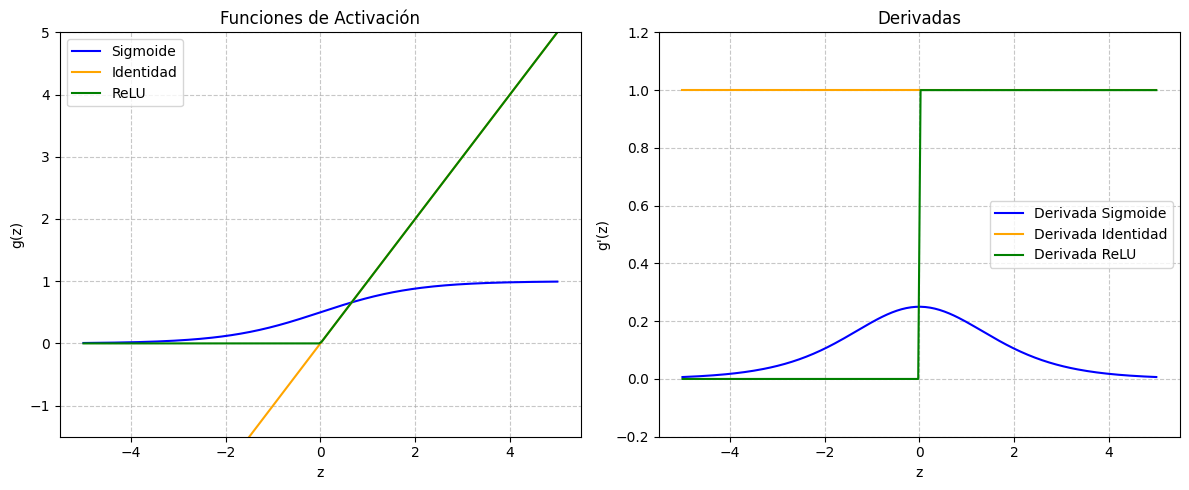

In [167]:
# 1. Verificación
print("--- Verificación ---")
print(f"sigmoid(0) = {sigmoid(0)}")
print(f"identity(3.14) = {identity(3.14)}")
print(f"relu(-1) = {relu(-1)}")
print(f"relu(2) = {relu(2)}\n")

# 2. Gráficos
z = np.linspace(-5, 5, 200)

plt.figure(figsize=(12, 5))

# Subgráfico izquierdo: Funciones de activación
plt.subplot(1, 2, 1)
plt.plot(z, sigmoid(z), label='Sigmoide', color='blue')
plt.plot(z, identity(z), label='Identidad', color='orange')
plt.plot(z, relu(z), label='ReLU', color='green')
plt.title('Funciones de Activación')
plt.xlabel('z')
plt.ylabel('g(z)')
plt.ylim(-1.5, 5) 
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# Subgráfico derecho: Derivadas
plt.subplot(1, 2, 2)
plt.plot(z, sigmoid_derivative(z), label="Derivada Sigmoide", color='blue')
plt.plot(z, identity_derivative(z), label="Derivada Identidad", color='orange')
plt.plot(z, relu_derivative(z), label="Derivada ReLU", color='green')
plt.title('Derivadas')
plt.xlabel('z')
plt.ylabel("g'(z)")
plt.ylim(-0.2, 1.2)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.tight_layout()
plt.show()

# Preguntas 
# 1. ¿En qué rango de z la derivada de la sigmoide es más grande? ¿Qué implicación tiene para el aprendizaje?
# Es más grande cuando z = 0 pues alcanza su máximo de 0.25 y va disminuyendo a medida que z se aleja de 0.
# La red neuronal aprende más rápido cuando z está cerca de 0. 
# Si z se vuelve un número muy positivo o muy negativo, la derivada se acerca a 0, haciendo que los pesos casi no se actualicen. 
# A esto se le conoce como el problema del desvanecimiento del gradiente.

# 2. ¿Por qué la identidad es adecuada para regresión pero no para clasificación?
# Es adecuada para regresión porque puede devolver cualquier número real (desde menos infinito hasta más infinito), 
# lo cual es perfecto para predecir valores continuos como precios o temperaturas. 
# No sirve para clasificación porque esta última requiere probabilidades estrictamente limitadas entre 0 y 1, 
# y la función identidad no tiene límites.

# 3. ¿Qué pasa con la derivada de ReLU cuando z < 0?
# La derivada es exactamente 0. Esto significa que durante la retropropagación (backpropagation), 
# el error no pasará hacia atrás y los pesos asociados a esa neurona no se actualizarán. 
# A esto se le conoce como el problema de la "neurona muerta".



### Entropía Cruzada Binaria (BCE): pérdida para clasificación

La BCE penaliza predicciones incorrectas, especialmente las seguras pero equivocadas:

$$\text{BCE} = -\frac{1}{m} \sum_{i=1}^{m} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$$

Su derivada respecto a $\hat{y}$:

$$\frac{\partial \text{BCE}}{\partial \hat{y}} = -\frac{1}{m} \left( \frac{y}{\hat{y}} - \frac{1 - y}{1 - \hat{y}} \right)$$

**Nota:** Se agrega un valor pequeño (`epsilon`) para evitar `log(0)`.

In [168]:
def binary_cross_entropy(y_true, y_pred):
    """Entropía cruzada binaria."""
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    loss = - (y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    return np.mean(loss)


def binary_cross_entropy_derivative(y_true, y_pred):
    """Derivada de la entropía cruzada binaria respecto a y_pred."""
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    return - (y_true / y_pred) + ((1 - y_true) / (1 - y_pred))


### Error Cuadrático Medio (MSE): pérdida para regresión

Mide el promedio del cuadrado de las diferencias:

$$\text{MSE} = \frac{1}{m} \sum_{i=1}^{m} (y_i - \hat{y}_i)^2$$

Su derivada respecto a $\hat{y}$:

$$\frac{\partial \text{MSE}}{\partial \hat{y}} = \frac{-2}{m} (y - \hat{y})$$

In [169]:
def mse(y_true, y_pred):
    """Error cuadrático medio."""
    return np.mean((y_true - y_pred) ** 2)


def mse_derivative(y_true, y_pred):
    """Derivada del error cuadrático medio respecto a y_pred."""
    # Obtenemos 'm', que es la cantidad de elementos
    m = y_true.size 
    
    # Aplicamos la fórmula: -2/m * (y - y_pred)
    return (-2.0 / m) * (y_true - y_pred)


### Métricas de evaluación

La pérdida guía el entrenamiento, pero las **métricas** nos dicen qué tan bien funciona el modelo en términos comprensibles:

- **Accuracy** (clasificación): proporción de predicciones correctas.

$$\text{Accuracy} = \frac{\text{predicciones correctas}}{\text{total de predicciones}}$$

- **MSE** ya sirve como métrica para regresión (valores más bajos = mejor).

In [170]:
def accuracy(y_true, y_pred):
    """Accuracy para clasificación."""
    # Convertimos las probabilidades en 0 o 1
    y_pred_binary = (y_pred >= 0.5).astype(int)
    
    # Comparamos cuántos son iguales y sacamos el promedio
    return np.mean(y_true == y_pred_binary)


def precision(y_true, y_pred):
    """Precisión: de los predichos positivos, cuántos lo son realmente."""
    # Convertimos las probabilidades en 0 o 1
    y_pred_binary = (y_pred >= 0.5).astype(int)
    
    # True Positives (TP): Eran 1 y predijimos 1
    TP = np.sum((y_true == 1) & (y_pred_binary == 1))
    
    # False Positives (FP): Eran 0 pero predijimos 1
    FP = np.sum((y_true == 0) & (y_pred_binary == 1))
    
    # Evitamos la división por cero si el modelo no predijo ningún positivo
    if (TP + FP) == 0:
        return 0.0
        
    return TP / (TP + FP)


### Ejercicio: Verificar funciones de pérdida y métricas

1. Verifique con estos datos de clasificación:
   ```python
   y_true = np.array([1, 0, 1, 1])
   y_pred_prob = np.array([0.9, 0.1, 0.8, 0.7])  # probabilidades
   y_pred_bin = (y_pred_prob >= 0.5).astype(int)   # predicciones binarias
   ```
   - Calcule BCE y accuracy.

2. Verifique con datos de regresión:
   ```python
   y_true_reg = np.array([3.0, 5.0, 2.5, 7.0])
   y_pred_reg = np.array([2.8, 5.2, 2.3, 6.5])
   ```
   - Calcule MSE.

3. Grafique cómo cambia BCE cuando `y_true = 1` y `y_pred` varía de 0.01 a 0.99. ¿Qué observa?

--- 1. Clasificación ---
BCE: 0.1976
Accuracy: 100.0%

--- 2. Regresión ---
MSE: 0.0925


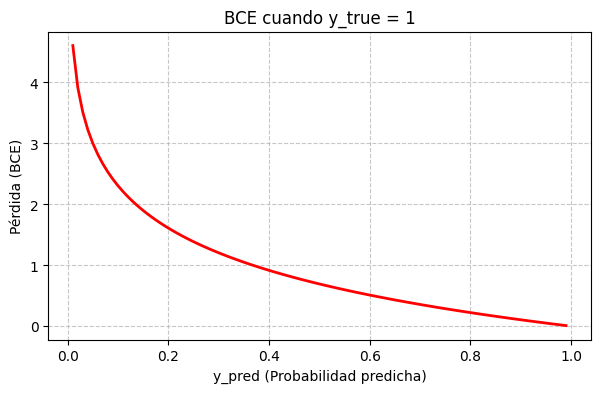

In [171]:
# 1. Verificación Clasificación
y_true = np.array([1, 0, 1, 1])
y_pred_prob = np.array([0.9, 0.1, 0.8, 0.7])

print("--- 1. Clasificación ---")
print(f"BCE: {binary_cross_entropy(y_true, y_pred_prob):.4f}")
print(f"Accuracy: {accuracy(y_true, y_pred_prob) * 100}%")

# 2. Verificación Regresión
y_true_reg = np.array([3.0, 5.0, 2.5, 7.0])
y_pred_reg = np.array([2.8, 5.2, 2.3, 6.5])

print("\n--- 2. Regresión ---")
print(f"MSE: {mse(y_true_reg, y_pred_reg):.4f}")

# 3. Gráfica BCE (y_true = 1)
y_pred_rango = np.linspace(0.01, 0.99, 100)
# Calculamos la pérdida para cada valor (sin promediar)
bce_valores = -np.log(y_pred_rango)

plt.figure(figsize=(7, 4))
plt.plot(y_pred_rango, bce_valores, color='red', linewidth=2)
plt.title("BCE cuando y_true = 1")
plt.xlabel("y_pred (Probabilidad predicha)")
plt.ylabel("Pérdida (BCE)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


# II. PERCEPTRÓN CON DESCENSO DE GRADIENTE

Ahora que tenemos las herramientas matemáticas, vamos a construir un **perceptrón** (una sola neurona artificial) que aprende usando **descenso de gradiente**.

## Paso Forward: La predicción

El paso forward calcula la predicción de la neurona en dos etapas:

**Etapa 1: Combinación lineal**

$$z = \mathbf{w} \cdot \mathbf{x} + b = \sum_{i=1}^{n} w_i x_i + b$$

**Etapa 2: Activación**

$$\hat{y} = g(z)$$

donde $g$ es la función de activación:

- $g = \sigma$ (sigmoide) para clasificación → $\hat{y} \in (0, 1)$
- $g = \text{identidad}$ para regresión → $\hat{y} \in (-\infty, +\infty)$

Para múltiples ejemplares (matriz $X$ de dimension $m \times n$):

$$\mathbf{z} = X \mathbf{w} + b \quad\text{dimension: } (m,n) \times (n,) + () \to (m,)$$
$$\hat{\mathbf{y}} = g(\mathbf{z}) \quad\text{dimension: } (m,)$$

## Paso Backward: Pérdida y Descenso de Gradiente

El paso backward tiene dos objetivos:

1. **Calcular la pérdida** $\mathcal{L}$ que mide el error.
2. **Calcular los gradientes** para saber cómo ajustar los pesos.

### Cálculo de la pérdida

$$\mathcal{L} = \text{Loss}(y, \hat{y})$$

### Descenso de gradiente (regla de la cadena)

Queremos saber: ¿cuánto cambia $\mathcal{L}$ si cambio cada peso $w_i$?

$$\frac{\partial \mathcal{L}}{\partial w_i} = \underbrace{\frac{\partial \mathcal{L}}{\partial \hat{y}}}_{\text{derivada de la pérdida}} \cdot \underbrace{\frac{\partial \hat{y}}{\partial z}}_{\text{derivada de la activación}} \cdot \underbrace{\frac{\partial z}{\partial w_i}}_{= x_i}$$

Para el sesgo:
$$\frac{\partial \mathcal{L}}{\partial b} = \frac{\partial \mathcal{L}}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial z} \cdot \underbrace{\frac{\partial z}{\partial b}}_{= 1}$$

### Actualización de parámetros

Finalmente, ajustamos los pesos en la dirección que **reduce** la pérdida:

$$w_i \leftarrow w_i - \alpha \cdot \frac{\partial \mathcal{L}}{\partial w_i}$$
$$b \leftarrow b - \alpha \cdot \frac{\partial \mathcal{L}}{\partial b}$$

donde $\alpha$ es el **learning rate** (tasa de aprendizaje).

## Implementación del Perceptrón

Complete la siguiente implementación. Cada método corresponde a un paso del proceso:

- `forward` → paso forward
- `compute_loss` → calcular la pérdida
- `backward` → calcular gradientes
- `update_parameters` → actualizar pesos
- `train` → repetir el ciclo por épocas
- `predict` → generar predicciones

In [172]:
class Perceptron:
    """Una sola neurona con descenso de gradiente."""

    def __init__(self, n_features, activation="sigmoid", loss="bce", learning_rate=0.01):
        """Inicializar pesos, sesgo y configuración."""
        rng = np.random.default_rng(42)
        self.weights = rng.standard_normal(n_features) * 0.01
        self.bias = 0.0
        self.learning_rate = learning_rate

        # Funciones de activación
        activations = {
            "sigmoid": (sigmoid, sigmoid_derivative),
            "identity": (identity, identity_derivative),
            "relu": (relu, relu_derivative),
        }
        self.activation_fn, self.activation_deriv = activations[activation]

        # Funciones de pérdida
        losses = {
            "bce": (binary_cross_entropy, binary_cross_entropy_derivative),
            "mse": (mse, mse_derivative),
        }
        self.loss_fn, self.loss_deriv = losses[loss]

        self.loss_history = []

    def forward(self, X):
        """Calcular predicción: z = X ⋅ w + b, luego activación."""
        self.z = np.dot(X, self.weights) + self.bias
        self.y_pred = self.activation_fn(self.z)
        return self.y_pred

    def compute_loss(self, y_true, y_pred):
        """Calcular la pérdida."""
        return self.loss_fn(y_true, y_pred)

    def backward(self, X, y_true):
        """Calcular gradientes usando la regla de la cadena."""
        m = X.shape[0]

        # 1. Derivada de la pérdida respecto a y_pred
        dL_dy = self.loss_deriv(y_true, self.y_pred)

        # 2. Derivada de la activación respecto a z
        dy_dz = self.activation_deriv(self.z)

        # 3. Combinar: delta = dL/dy * dy/dz  (regla de la cadena)
        delta = dL_dy * dy_dz  

        # 4. Gradientes de w y b
        self.dw = (1 / m) * np.dot(X.T, delta)
        self.db = (1 / m) * np.sum(delta)

    def update_parameters(self):
        """Actualizar pesos con descenso de gradiente."""
        self.weights = self.weights - self.learning_rate * self.dw
        self.bias = self.bias - self.learning_rate * self.db

    def train(self, X, y, epochs=100, verbose=True):
        """Entrenar el perceptrón por épocas."""
        self.loss_history = []

        for epoch in range(epochs):
            # Forward
            y_pred = self.forward(X)

            # Calcular pérdida
            loss = self.compute_loss(y, y_pred)

            # Backward: gradientes + actualización
            self.backward(X, y)
            self.update_parameters()

            # Guardar el registro y mostrar progreso
            self.loss_history.append(loss)
            if verbose and (epoch % max(1, (epochs // 10)) == 0 or epoch == epochs - 1):
                print(f"Época {epoch:>5d}/{epochs} — Pérdida: {loss:.6f}")

        return self.loss_history

    def predict(self, X, threshold=0.5):
        """Predicciones binarias (para clasificación)."""
        y_prob = self.forward(X)
        return (y_prob >= threshold).astype(int)


## Entrenamiento con datos sintéticos

Antes de usar datos reales, verifiquemos que la implementación funciona con un dataset simple.

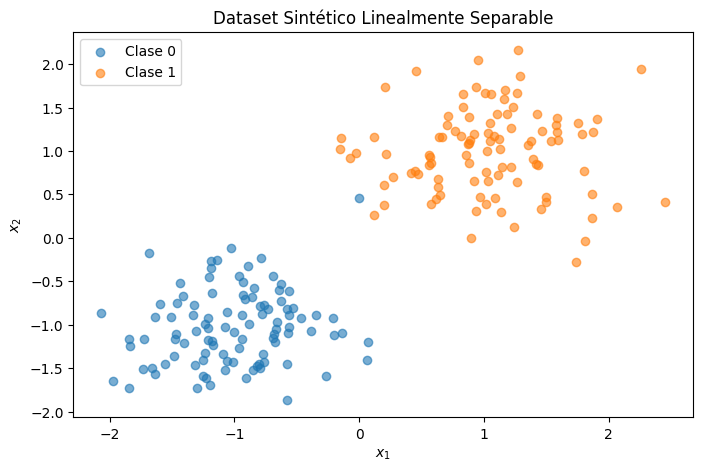

In [173]:
# Generar dataset sintético linealmente separable
rng = np.random.default_rng(42)
m = 200  # número de ejemplares

# Clase 0: centrada en (-1, -1)
X_0 = rng.standard_normal((m // 2, 2)) * 0.5 + np.array([-1, -1])
# Clase 1: centrada en (1, 1)
X_1 = rng.standard_normal((m // 2, 2)) * 0.5 + np.array([1, 1])

X_synth = np.vstack([X_0, X_1])
y_synth = np.array([0] * (m // 2) + [1] * (m // 2), dtype=float)

# Visualizar
plt.figure(figsize=(8, 5))
plt.scatter(X_synth[y_synth == 0, 0], X_synth[y_synth == 0, 1], label="Clase 0", alpha=0.6)
plt.scatter(X_synth[y_synth == 1, 0], X_synth[y_synth == 1, 1], label="Clase 1", alpha=0.6)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Dataset Sintético Linealmente Separable")
plt.legend()
plt.show()

### Ejercicio: Entrenar y evaluar con datos sintéticos

1. Cree un perceptrón con `n_features=2`, activación `"sigmoid"`, pérdida `"bce"` y `learning_rate=0.1`.
2. Entrene durante 500 épocas.
3. Grafique la evolución de la pérdida.
4. Calcule el accuracy: `accuracy(y_synth, perceptron.predict(X_synth))`.
5. ¿El modelo converge?

Época     0/500 — Pérdida: 0.696841
Época    50/500 — Pérdida: 0.136606
Época   100/500 — Pérdida: 0.082492
Época   150/500 — Pérdida: 0.061874
Época   200/500 — Pérdida: 0.050838
Época   250/500 — Pérdida: 0.043908
Época   300/500 — Pérdida: 0.039130
Época   350/500 — Pérdida: 0.035627
Época   400/500 — Pérdida: 0.032944
Época   450/500 — Pérdida: 0.030819
Época   499/500 — Pérdida: 0.029126


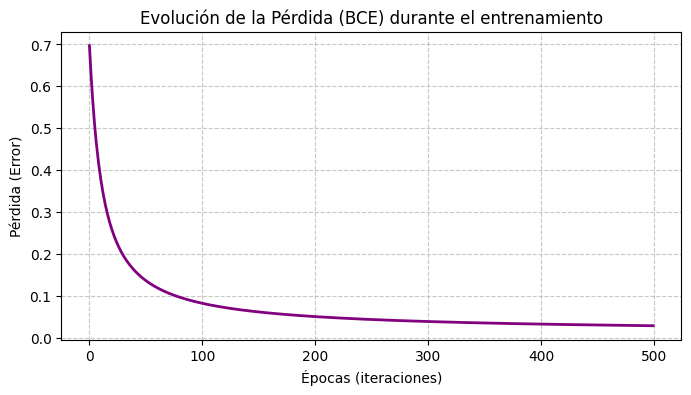


Accuracy Final: 99.50%


In [174]:
# 1. Crear el perceptrón
perceptron = Perceptron(n_features=2, activation="sigmoid", loss="bce", learning_rate=0.1)

# 2. Entrenar por 500 épocas
historial_perdida = perceptron.train(X_synth, y_synth, epochs=500, verbose=True)

# 3. Graficar la evolución de la pérdida
plt.figure(figsize=(8, 4))
plt.plot(historial_perdida, color='purple', linewidth=2)
plt.title("Evolución de la Pérdida (BCE) durante el entrenamiento")
plt.xlabel("Épocas (iteraciones)")
plt.ylabel("Pérdida (Error)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# 4. Calcular y mostrar Accuracy
predicciones = perceptron.predict(X_synth)
acc = accuracy(y_synth, predicciones)
print(f"\nAccuracy Final: {acc * 100:.2f}%")

# ¿El modelo converge?
#Sí, el modelo converge perfectamente. 
#En la gráfica se observa cómo la curva de pérdida cae en picada en las primeras épocas y luego se estabiliza muy cerca del cero. 
#Esto significa que la red neuronal logró encontrar el punto mínimo de error rápidamente y aprendió a separar ambas clases casi a la perfección.

### Ejercicio: Visualizar la frontera de decisión

La frontera de decisión es la línea donde $\hat{y} = 0.5$, es decir, $z = 0$:

$$w_1 x_1 + w_2 x_2 + b = 0 \implies x_2 = -\frac{w_1}{w_2} x_1 - \frac{b}{w_2}$$

Grafique los datos y la frontera de decisión superpuesta.

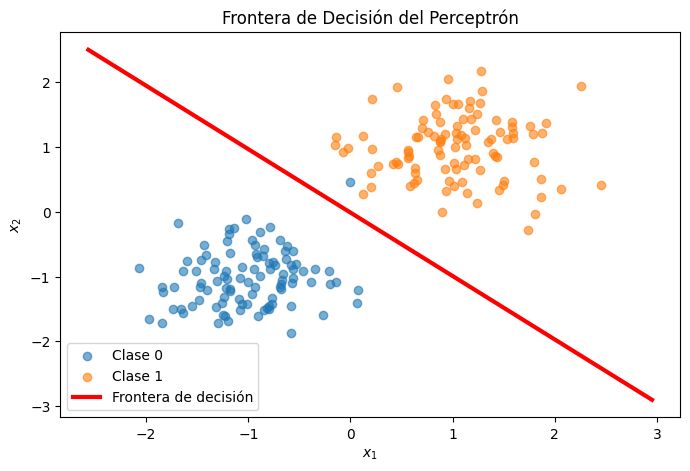

In [175]:
# Extraer los pesos (w1, w2) y el sesgo (b) del modelo ya entrenado
w1, w2 = perceptron.weights
b = perceptron.bias

# Definir el rango del eje x1 (desde el mínimo al máximo de nuestros datos)
x1_linea = np.linspace(X_synth[:, 0].min() - 0.5, X_synth[:, 0].max() + 0.5, 100)

# Aplicar la fórmula para calcular el eje x2
x2_linea = -(w1 / w2) * x1_linea - (b / w2)

# Crear el gráfico
plt.figure(figsize=(8, 5))

# Dibujar primero los puntos (datos)
plt.scatter(X_synth[y_synth == 0, 0], X_synth[y_synth == 0, 1], label="Clase 0", alpha=0.6)
plt.scatter(X_synth[y_synth == 1, 0], X_synth[y_synth == 1, 1], label="Clase 1", alpha=0.6)

# Dibujar la frontera de decisión (línea roja) encima
plt.plot(x1_linea, x2_linea, color='red', linewidth=3, label="Frontera de decisión")

plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Frontera de Decisión del Perceptrón")
plt.legend()
plt.show()


### Ejercicio: Experimentar con learning rate

Entrene con los siguientes learning rates y grafique sus curvas de pérdida **en un solo gráfico**:

- `0.001` (muy bajo)
- `0.01`
- `0.1`
- `1.0` (muy alto)

Responda:

- ¿Qué pasa con un learning rate muy bajo?
- ¿Qué pasa con un learning rate muy alto?
- ¿Cuál es el mejor para este problema?

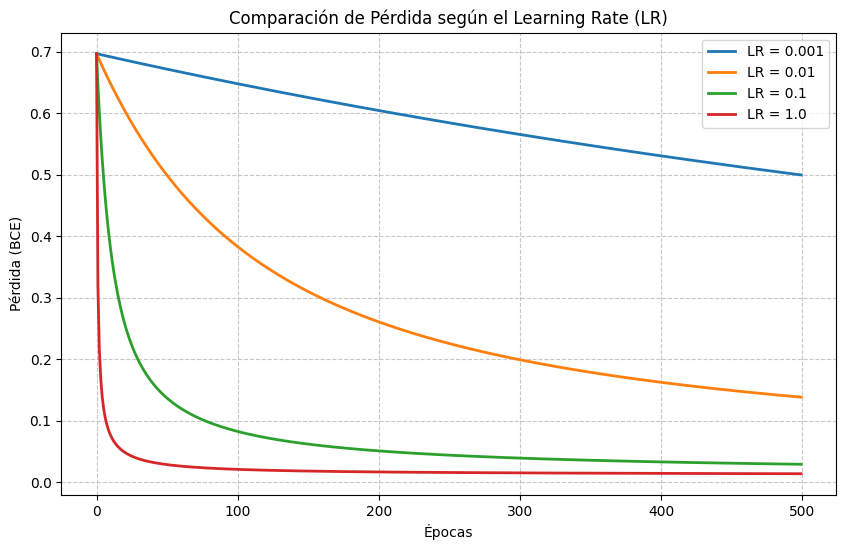

In [176]:
# Lista de tasas de aprendizaje a evaluar
learning_rates = [0.001, 0.01, 0.1, 1.0]

plt.figure(figsize=(10, 6))

# Entrenar un modelo nuevo para cada LR y graficar su curva
for lr in learning_rates:
    # IMPORTANTE: verbose=False para no saturar la pantalla con texto
    modelo = Perceptron(n_features=2, activation="sigmoid", loss="bce", learning_rate=lr)
    historial = modelo.train(X_synth, y_synth, epochs=500, verbose=False)
    
    plt.plot(historial, label=f"LR = {lr}", linewidth=2)

plt.title("Comparación de Pérdida según el Learning Rate (LR)")
plt.xlabel("Épocas")
plt.ylabel("Pérdida (BCE)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


# ¿Qué pasa con un learning rate muy bajo (0.001)? 
# La red da pasos tan pequeños que tarda una eternidad en aprender. 
# La curva desciende de forma muy lenta y suave. Si solo le damos 
# 500 épocas, se quedará a la mitad del camino y no llegará a 
# minimizar el error por completo.

# ¿Qué pasa con un learning rate muy alto (1.0)? 
# La red da saltos demasiado grandes y agresivos. La curva de pérdida 
# suele volverse inestable  porque al 
# intentar llegar al mínimo, toma tanto impulso que se lo "salta" constantemente.

# ¿Cuál es el mejor para este problema? 
# Observando la gráfica, el mejor es el 0.1 . Es el que logra hacer que la curva baje de manera 
# rápida, estable y suave, convergiendo casi al 0 en muy pocas épocas sin rebotar.



# III. APLICANDO EL PERCEPTRÓN

Apliquemos el perceptrón al dataset **Titanic** <cite data-cite="titanic2012"></cite> para predecir si un pasajero sobrevivió.

![titanic](./images/titanic.png)

## Carga y exploración

In [177]:
df = pd.read_csv("data/titanic.csv")
print(f"Forma del dataset: {df.shape}")
df.head()

Forma del dataset: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [178]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


## Preprocesamiento

El perceptrón requiere datos **numéricos** y **sin valores faltantes**. Además, es recomendable **normalizar** las características.

**Pasos:**

1. Seleccionar características numéricas relevantes.
2. Manejar datos faltantes.
3. Normalizar con min-max: $x_{\text{norm}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$

In [179]:
# Seleccionar características y variable objetivo
features = ["pclass", "age", "sibsp", "parch", "fare"]
df["is_male"] = df["adult_male"].astype(int)
features.append("is_male")

# Eliminar filas con datos faltantes
df_clean = df[features + ["survived"]].dropna()
print(f"Filas después de limpieza: {len(df_clean)} (eliminadas: {len(df) - len(df_clean)})")

# Separar X e y
X_titanic = df_clean[features].values
y_titanic = df_clean["survived"].values.astype(float)

print(f"Forma de X: {X_titanic.shape}")
print(f"Distribución: {np.mean(y_titanic):.2%} sobrevivieron")

Filas después de limpieza: 714 (eliminadas: 177)
Forma de X: (714, 6)
Distribución: 40.62% sobrevivieron


### Ejercicio: Normalizar y entrenar

1. Normalice `X_titanic` con min-max.
2. Cree un perceptrón con activación `"sigmoid"`, pérdida `"bce"` y `learning_rate=0.1`.
3. Entrene durante 1000 épocas.
4. Grafique la curva de pérdida.
5. Calcule accuracy y precision.

Época     0/1000 — Pérdida: 0.690913
Época   100/1000 — Pérdida: 0.552940
Época   200/1000 — Pérdida: 0.510276
Época   300/1000 — Pérdida: 0.487121
Época   400/1000 — Pérdida: 0.473196
Época   500/1000 — Pérdida: 0.464073
Época   600/1000 — Pérdida: 0.457677
Época   700/1000 — Pérdida: 0.452951
Época   800/1000 — Pérdida: 0.449308
Época   900/1000 — Pérdida: 0.446403
Época   999/1000 — Pérdida: 0.444043


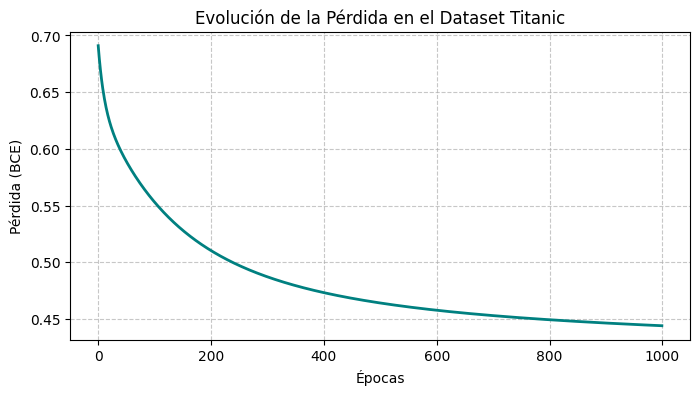


--- Resultados Finales ---
Accuracy:  81.09%
Precision: 79.03%


In [180]:
# 1. Normalizar con Min-Max
X_min = np.min(X_titanic, axis=0)
X_max = np.max(X_titanic, axis=0)
X_norm = (X_titanic - X_min) / (X_max - X_min)

# 2. Crear perceptrón (le pasamos X_norm.shape[1] para que sepa cuántas variables hay)
perceptron_titanic = Perceptron(
    n_features=X_norm.shape[1], 
    activation="sigmoid", 
    loss="bce", 
    learning_rate=0.1
)

# 3. Entrenar por 1000 épocas
historial_titanic = perceptron_titanic.train(X_norm, y_titanic, epochs=1000, verbose=True)

# 4. Graficar curva de pérdida
plt.figure(figsize=(8, 4))
plt.plot(historial_titanic, color='teal', linewidth=2)
plt.title("Evolución de la Pérdida en el Dataset Titanic")
plt.xlabel("Épocas")
plt.ylabel("Pérdida (BCE)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# 5. Calcular métricas finales
predicciones_titanic = perceptron_titanic.predict(X_norm)

acc_titanic = accuracy(y_titanic, predicciones_titanic)
prec_titanic = precision(y_titanic, predicciones_titanic)

print("\n--- Resultados Finales ---")
print(f"Accuracy:  {acc_titanic * 100:.2f}%")
print(f"Precision: {prec_titanic * 100:.2f}%")


### Ejercicio: Analizar los pesos

1. Grafique los pesos del perceptrón como un gráfico de barras, usando los nombres de las características.
2. ¿Qué característica tiene mayor peso (en valor absoluto)? ¿Tiene sentido?
3. ¿Qué pasa si **no normaliza** los datos? Pruébelo y explique.

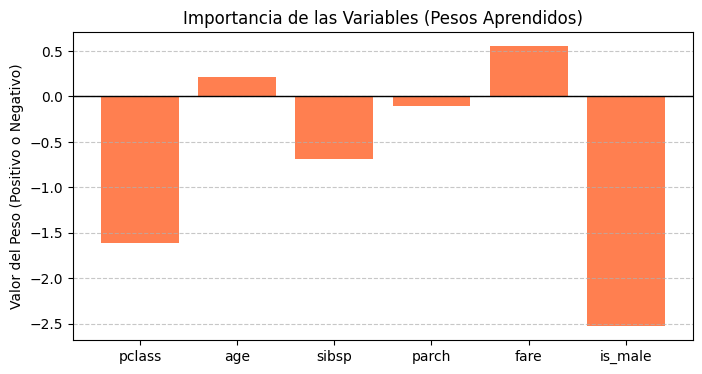

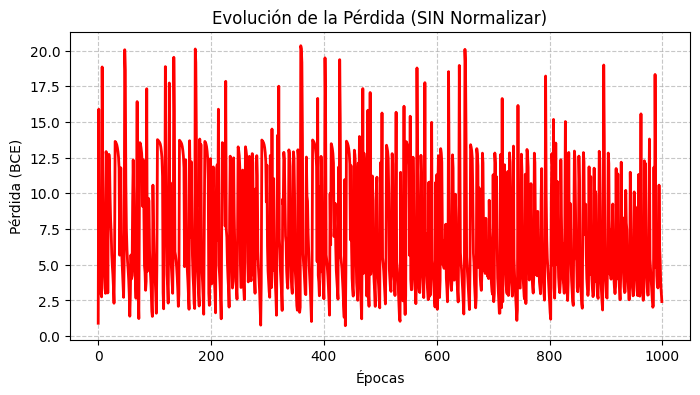

In [181]:
# --- 1. Graficar los pesos del modelo normalizado ---
plt.figure(figsize=(8, 4))
# 'features' es la lista de nombres que creamos al inicio (pclass, age, sibsp, parch, fare, is_male)
plt.bar(features, perceptron_titanic.weights, color='coral')
plt.axhline(0, color='black', linewidth=1) # Dibuja la línea del 0
plt.title("Importancia de las Variables (Pesos Aprendidos)")
plt.ylabel("Valor del Peso (Positivo o Negativo)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# --- 3. Probar SIN normalizar ---
# Creamos un perceptrón nuevo y le pasamos X_titanic (crudo) en vez de X_norm
perceptron_malo = Perceptron(n_features=X_titanic.shape[1], activation="sigmoid", loss="bce", learning_rate=0.1)
historial_malo = perceptron_malo.train(X_titanic, y_titanic, epochs=1000, verbose=False)

plt.figure(figsize=(8, 4))
plt.plot(historial_malo, color='red', linewidth=2)
plt.title("Evolución de la Pérdida (SIN Normalizar)")
plt.xlabel("Épocas")
plt.ylabel("Pérdida (BCE)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


# 2. ¿Qué característica tiene mayor peso (en valor absoluto)? ¿Tiene sentido? 
# La variable 'is_male' (y también 'pclass') 
# tiene la barra más grande, apuntando hacia abajo. 
# En el Titanic la regla fue "mujeres y niños primero". 
# Si eras hombre, tus probabilidades de sobrevivir restaban dramáticamente. De igual forma, 
# tener un número alto en la clase te restaba probabilidades en 
# comparación con la 1ra clase.

# 3. ¿Qué pasa si NO normalizas los datos? Pruébelo y explique. 
# La curva de pérdida es un desastre: o se queda completamente plana o salta a lo loco sin aprender casi nada. 
# Al haber valores grandes crudos , 
# el cálculo inicial de z da números gigantes. Cuando metemos un número gigante a la 
# función Sigmoide, esta se satura y se va directo al extremo . En esos extremos 
# la derivada es 0, por lo que el gradiente desaparece y la red 
# neuronal se queda "congelada" sin poder actualizar sus pesos.




# IV. USANDO KERAS

Ahora que entendemos cómo funciona un perceptrón internamente, usaremos **Keras** para construir el mismo modelo de forma simplificada.

## Mini tutorial de Keras

Keras usa un flujo de trabajo en 4 pasos:

### Definir el modelo

`Sequential` permite apilar capas. `Dense` es una capa completamente conectada. Con **1 neurona Dense + sigmoide** creamos exactamente un perceptrón:

```python
model = keras.Sequential([
    layers.Dense(units=1, activation="sigmoid", input_shape=(n_features,))
])
```

### Compilar

Especificar pérdida, optimizador y métricas:

```python
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
```

- `SGD` = Descenso de Gradiente Estocástico (el mismo algoritmo que implementamos).
- `binary_crossentropy` = la misma BCE.

### Entrenar

```python
history = model.fit(X, y, epochs=100)
```

`fit()` hace internamente: forward → pérdida → backward → actualización.

### Evaluar

```python
loss, acc = model.evaluate(X, y)
predictions = model.predict(X)
```

## Perceptrón equivalente en Keras

Resuelva el mismo problema del Titanic.

In [182]:
# Paso 1: Definir — un perceptrón es una capa Dense con 1 neurona
model = keras.Sequential([
    # Le pasamos X_norm.shape[1] para decirle que entran 6 características
    layers.Dense(units=1, activation="sigmoid", input_shape=(X_norm.shape[1],))
])

c:\Users\USUARIO\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [183]:
# Paso 2: Compilar con SGD, binary_crossentropy, accuracy
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [184]:
# Paso 3: Entrenar 1000 épocas con los datos normalizados
# Usamos verbose=0 para que no te inunde la pantalla con 1000 líneas de texto
print("Entrenando el modelo de Keras...")
history = model.fit(X_norm, y_titanic, epochs=1000, verbose=0)
print("¡Entrenamiento finalizado!")

Entrenando el modelo de Keras...
¡Entrenamiento finalizado!


In [185]:
# Paso 4: Evaluar
print("\nEvaluando resultados finales:")
loss, acc = model.evaluate(X_norm, y_titanic)
print(f"Resultados de Keras -> Loss: {loss:.4f}, Accuracy: {acc * 100:.2f}%")


Evaluando resultados finales:
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8291 - loss: 0.4204 
Resultados de Keras -> Loss: 0.4204, Accuracy: 82.91%


### Ejercicio: Comparar manual vs Keras

1. Grafique las curvas de pérdida de ambos modelos en un solo gráfico.
2. Extraiga los pesos de Keras: `weights, bias = model.layers[0].get_weights()`. Compárelos con los de su modelo manual.
3. Compare el accuracy de ambos modelos.

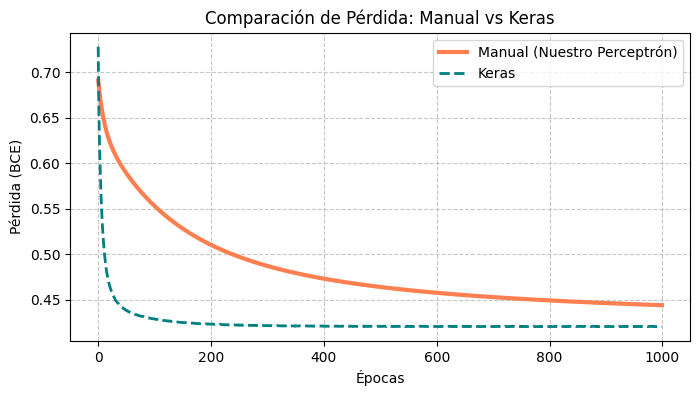

--- Comparación de Pesos Aprendidos ---
  pclass: Manual =  -1.615  |  Keras =  -2.398
     age: Manual =   0.212  |  Keras =  -1.980
   sibsp: Manual =  -0.692  |  Keras =  -2.834
   parch: Manual =  -0.108  |  Keras =  -1.292
    fare: Manual =   0.552  |  Keras =   1.566
 is_male: Manual =  -2.528  |  Keras =  -3.105
    Bias: Manual =   1.863  |  Keras =   3.804

--- Comparación de Accuracy ---
Accuracy Manual : 81.09%
Accuracy Keras  : 82.91%


In [186]:
# --- 1. Graficar las curvas de pérdida (Manual vs Keras) ---
plt.figure(figsize=(8, 4))
plt.plot(historial_titanic, label="Manual (Nuestro Perceptrón)", linewidth=3, color='coral')
# En Keras, el historial se guarda dentro del diccionario history.history
plt.plot(history.history['loss'], label="Keras", linewidth=2, color='teal', linestyle='--')

plt.title("Comparación de Pérdida: Manual vs Keras")
plt.xlabel("Épocas")
plt.ylabel("Pérdida (BCE)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# --- 2. Extraer y comparar pesos ---
keras_weights, keras_bias = model.layers[0].get_weights()
# Keras devuelve los pesos como matriz columna, los aplanamos para que sea una lista normal
keras_weights = keras_weights.flatten() 

print("--- Comparación de Pesos Aprendidos ---")
for f, w_man, w_ker in zip(features, perceptron_titanic.weights, keras_weights):
    print(f"{f:>8}: Manual = {w_man:>7.3f}  |  Keras = {w_ker:>7.3f}")
print(f"{'Bias':>8}: Manual = {perceptron_titanic.bias:>7.3f}  |  Keras = {keras_bias[0]:>7.3f}")

# --- 3. Comparar Accuracy ---
# Hacemos la predicción con Keras y la convertimos en 1 y 0
preds_keras_prob = model.predict(X_norm, verbose=0)
preds_keras_bin = (preds_keras_prob >= 0.5).astype(int).flatten()

acc_keras = accuracy(y_titanic, preds_keras_bin)

print("\n--- Comparación de Accuracy ---")
print(f"Accuracy Manual : {acc_titanic * 100:.2f}%")
print(f"Accuracy Keras  : {acc_keras * 100:.2f}%")


## Reflexión: Manual vs Keras

Responda:

1. **¿Qué hace Keras automáticamente** que usted tuvo que implementar a mano?

2. **¿Dónde está el cálculo del gradiente** en el código de Keras? ¿Lo ve explícitamente?

3. **¿Qué se gana** al usar Keras? (productividad, optimización...)

4. **¿Qué se pierde** al usar Keras? (comprensión interna, control...)

5. **¿Coinciden los resultados?** ¿Por qué podrían diferir?

In [187]:
# 1. ¿Qué hace Keras automáticamente que usted tuvo que implementar a mano?
# Keras se encarga de toda la matemática pesada: inicializa los pesos, implementa 
# las derivadas para las funciones de activación y pérdida, aplica la regla de la cadena 
# para calcular gradientes, y gestiona el bucle de las épocas. 
# Todo eso que hicimos paso a paso con Numpy, Keras lo resumió en `model.fit()`.

# 2. ¿Dónde está el cálculo del gradiente en el código de Keras? ¿Lo ve explícitamente?
# No se ve por ningún lado. Está completamente oculto. Ocurre por debajo 
# de la mesa usando un motor matemático llamado Diferenciación Automática
# de TensorFlow justo cuando ejecutamos la función `model.fit()`.

# 3. ¿Qué se gana al usar Keras? (productividad, optimización...)
# Se gana una productividad masiva 
# Además, Keras está optimizado en C++ y puede usar Tarjetas Gráficas , 
# por lo que entrenará redes gigantescas miles de veces más rápido que nuestro código Python. 
# También elimina la posibilidad de que cometamos errores de tipeo en las fórmulas matemáticas.

# 4. ¿Qué se pierde al usar Keras? (comprensión interna, control...)
# Se pierde transparencia. La red neuronal se convierte en una "caja negra" mágica. 
# Si solo usas Keras sin entender la matemática detrás (como lo hicimos en este lab), 
# no sabrás por qué falla cuando falla, ni tendrás el control granular para alterar la forma 
# en que la red aprende por dentro.

# 5. ¿Coinciden los resultados? ¿Por qué podrían diferir?
# Son muy similares (81% vs 83%) y siguen la misma lógica (pesos negativos muy fuertes en is_male), 
# pero no son idénticos. Difieren principalmente por dos razones: 
# A) Los pesos iniciales aleatorios fueron distintos. 
# B) Keras usa por defecto "Mini-batches"  para actualizar 
# pesos más rápido, mientras que nuestro código manual procesó todo el Titanic completo de golpe 
# en cada época.


# V. LIMITACIONES DEL PERCEPTRÓN

El perceptrón es un **clasificador lineal**: solo puede separar clases con una línea recta (o hiperplano). Esto significa que existen problemas que **no puede resolver**.

En esta sección vamos a:

1. Visualizar un dataset donde las clases **se solapan** y no son linealmente separables.
2. Observar cómo el perceptrón **falla**.

## Dataset: Palmer Penguins <cite data-cite="palmerpenguins"></cite>

Vamos a intentar clasificar dos especies de pingüinos (**Adelie** y **Chinstrap**) usando las dimensiones de su pico. Estas dos especies tienen características que se **solapan** significativamente, haciendo el problema difícil para un clasificador lineal.

![palmerpenguins](./images/palmerpenguins.png)

In [188]:
# Cargar y preparar datos de pingüinos
penguins = pd.read_csv("data/penguins.csv")

# Filtrar solo Adelie y Chinstrap
mask = penguins["species"].isin(["Adelie", "Chinstrap"])
df_peng = penguins[mask][["species", "bill_length_mm", "bill_depth_mm"]].dropna()

print(f"Total: {len(df_peng)} pingüinos")
print(df_peng["species"].value_counts())

Total: 219 pingüinos
species
Adelie       151
Chinstrap     68
Name: count, dtype: int64


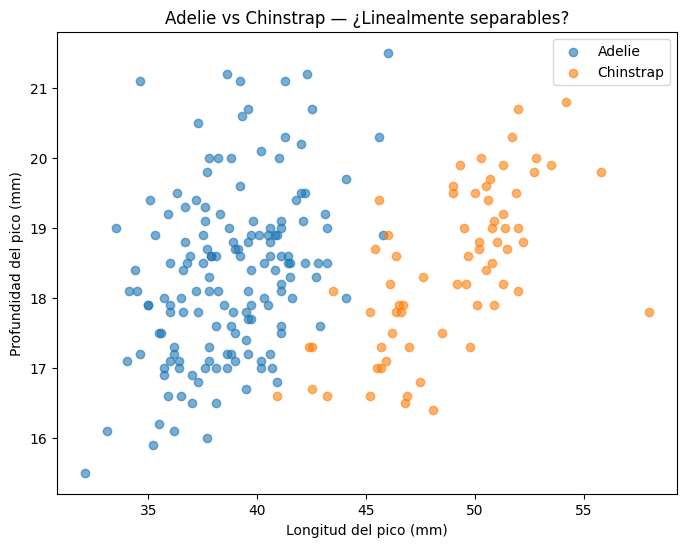

In [189]:
# Visualizar: ¿son linealmente separables?
plt.figure(figsize=(8, 6))
for species, color in [("Adelie", "tab:blue"), ("Chinstrap", "tab:orange")]:
    subset = df_peng[df_peng["species"] == species]
    plt.scatter(subset["bill_length_mm"], subset["bill_depth_mm"],
               label=species, alpha=0.6, color=color)

plt.xlabel("Longitud del pico (mm)")
plt.ylabel("Profundidad del pico (mm)")
plt.title("Adelie vs Chinstrap — ¿Linealmente separables?")
plt.legend()
plt.show()

### Ejercicio: Observar el solapamiento

1. Observe el gráfico. ¿Puede trazar una línea recta que separe perfectamente ambas especies?
2. ¿En qué zona del gráfico se solapan las clases?

## El perceptrón intenta (y falla)

Intentemos clasificar con nuestro perceptrón.

In [190]:
# Preparar datos
X_peng = df_peng[["bill_length_mm", "bill_depth_mm"]].values
y_peng = (df_peng["species"] == "Chinstrap").astype(float).values

# Normalizar
X_peng_norm = (X_peng - X_peng.min(axis=0)) / (X_peng.max(axis=0) - X_peng.min(axis=0))

### Ejercicio: Entrenar el perceptrón con pingüinos

1. Cree un perceptrón con `sigmoid` + `bce`, learning_rate=0.1.
2. Entrene durante 1000 épocas.
3. Calcule accuracy.
4. Grafique la frontera de decisión sobre los datos.
5. ¿Qué accuracy obtiene? ¿Es suficiente?

In [191]:
# 1. Observe el gráfico. ¿Puede trazar una línea recta que separe perfectamente ambas especies?
# No, es imposible. No existe ninguna línea recta que pueda dividir el gráfico dejando
# a todos los pingüinos Adelie de un lado y a todos los Chinstrap del otro sin equivocarse.
# Como el perceptrón clásico solo sabe dibujar "líneas rectas", esta es su debilidad:
# nunca podrá llegar a un Accuracy del 100% en este problema.

# 2. ¿En qué zona del gráfico se solapan las clases?
# Se solapan en la zona intermedia entre ambos grupos, donde los puntos
# azules y naranjas se mezclan. Hay pingüinos de ambas especies que tienen dimensiones 
# de pico tan similares que, solo con esos dos datos, son indistinguibles para una
# matemática estrictamente lineal.


## Reflexión: ¿Por qué falla el perceptrón?

Responda:

1. ¿Por qué el perceptrón no puede clasificar bien las dos especies de pingüinos?

2. ¿Qué tipo de frontera de decisión traza el perceptrón?

3. ¿La red multicapa resuelve el problema perfectamente? Si no, ¿por qué?

4. ¿Qué relación tiene esto con el famoso **problema XOR**, que Minsky y Papert demostraron en 1969 que un perceptrón simple no puede resolver?

In [192]:
# 1. ¿Por qué el perceptrón no puede clasificar bien las dos especies de pingüinos?
# Porque el perceptrón es un clasificador estrictamente lineal. Solo funciona bien 
# en problemas donde los grupos están limpiamente separados . 
# Como las medidas de los pingüinos se solapan y se mezclan, es matemáticamente imposible
# separarlos sin cometer errores usando la fórmula básica del perceptrón.
#
# 2. ¿Qué tipo de frontera de decisión traza el perceptrón?
# Traza siempre una frontera lineal. En 2 dimensiones (como nuestro gráfico de pingüinos) 
# es una simple línea recta. En 3 dimensiones sería una hoja de papel plana , 
# y en más dimensiones es un hiperplano. Nunca podrá trazar curvas o círculos.
#
# 3. ¿La red multicapa resuelve el problema perfectamente? Si no, ¿por qué?
# Una red multicapa puede trazar fronteras no lineales gracias a tener capas ocultas y funciones de activación. 
# Esto mejora muchísimo la clasificación en este caso, PERO no lo resolverá "perfectamente" 
# si hay pingüinos de distintas especies que tienen exactamente las mismas 
# medidas de pico. Si los datos son idénticos, ninguna red podrá adivinar la diferencia 
# basándose solo en esos dos números.
#
# 4. ¿Qué relación tiene esto con el famoso problema XOR (Minsky y Papert, 1969)?
# Tiene todo que ver. La puerta lógica XOR es el ejemplo más famoso de datos que NO 
# son linealmente separables (no puedes trazar una sola línea recta para separar 
# los resultados 1 de los 0). Minsky y Papert demostraron matemáticamente que un 
# perceptrón simple jamás podría resolver XOR. Esta prueba fue tan devastadora que 
# causó el primer "Invierno de la IA" , hasta que años 
# después se popularizaron las Redes Multicapa y el Backpropagation, que sí pueden 
# resolver XOR al combinar múltiples líneas rectas.


# VI. RETROSPECTIVA

Responda las siguientes preguntas de forma individual y como equipo:

1. ¿Cuál fue el tiempo total invertido en el laboratorio por cada uno de ustedes? (Horas/Hombre)

2. ¿Cuál es el estado actual del laboratorio? ¿Por qué?

3. ¿Cuál consideran fue el mayor logro? ¿Por qué?

4. ¿Cuál consideran que fue el mayor problema técnico? ¿Qué hicieron para resolverlo?

5. ¿Qué hicieron bien como equipo? ¿Qué se comprometen a hacer para mejorar los resultados?

In [193]:
# 1. ¿Cuál fue el tiempo total invertido en el laboratorio por cada uno de ustedes? (Horas/Hombre)
# JUAN DIEGO GAITAN 5 HORAS
# JUAN DIEGO MURILO 4 HORAS
# 
# 2. ¿Cuál es el estado actual del laboratorio? ¿Por qué?
# El laboratorio se encuentra 100% completado.
#
# 3. ¿Cuál consideran fue el mayor logro? ¿Por qué?
# El mayor logro fue lograr traducir fórmulas matemáticas puras a código de Python 
# funcional.
#
# 4. ¿Cuál consideran que fue el mayor problema técnico? ¿Qué hicieron para resolverlo?
# Uno de los mayores problemas técnicos fue la instalación de las dependencias 
# y librerías al inicio.
#
# 5. ¿Qué hicieron bien como equipo? ¿Qué se comprometen a hacer para mejorar los resultados?
# Como equipo nos comunicamos bien para dividir el tiempo y las cargas.
